In [1]:
from rubin_sim.phot_utils import calc_snr_m5, PhotometricParameters, Bandpass, Sed
import numpy as np
import os
from rubin_scheduler.data import get_data_dir
import matplotlib.pylab as plt
%matplotlib inline
from rubin_sim.maf.utils import m52snr

In [2]:
magnitudes = np.arange(20) + 15
m5 = 20

In [3]:

throughputs_dir = os.path.join(get_data_dir(), "throughputs")
band = "g"
bp = Bandpass()
bp.read_throughput(os.path.join(throughputs_dir, "baseline/total_%s.dat" % band))
bp_hw = Bandpass()
bp_hw.read_throughput(os.path.join(throughputs_dir, "baseline/hardware_%s.dat" % band))
pp = PhotometricParameters(bandpass=band)

source = Sed()
source.set_flat_sed()
source.multiply_flux_norm(0.00000001)
source.calc_mag(bp)

np.float64(20.0)

In [4]:
source.calc_adu(bp, pp)

np.float64(31758.52103473091)

In [5]:
snr, gamma = calc_snr_m5(magnitudes, bp, m5, pp)
snr_maf = m52snr(magnitudes, m5)

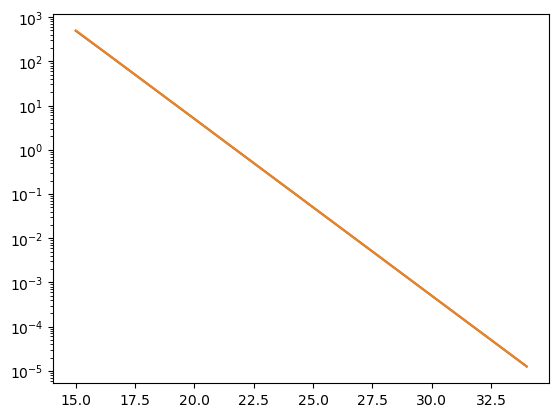

In [6]:
plt.semilogy(magnitudes, snr)
plt.semilogy(magnitudes, snr_maf)

In [7]:
def m52snr_source(m, m5, gamma=0.04):
    if gamma is None:
        snr = 5.0 * 10.0 ** (-0.4 * (m - m5))
    else:
        xval = np.power(10, 0.2 * (m - m5))
        snr = 1 / np.sqrt((0.04 - gamma) * xval + gamma * xval * xval)
    return snr


In [8]:
snr_source = m52snr_source(magnitudes, m5)

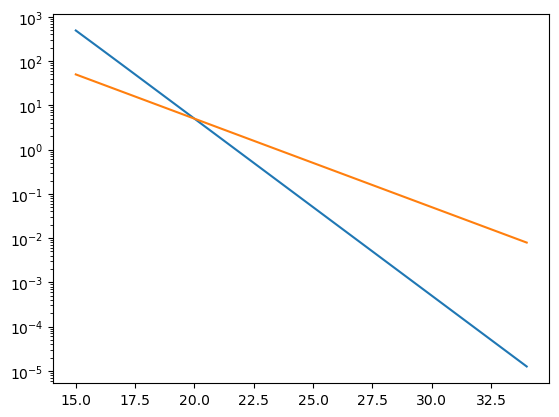

In [9]:
plt.semilogy(magnitudes, snr)
plt.semilogy(magnitudes, snr_source)
